# Apollo lunar seismic waveform download tutorial

Kwun Hei Fong & Qili Andy Dai

Contact: qilidai@cuhk.edu.hk

The Apollo missions deployed five seismic stations on the lunar nearside between 1969 and 1972 (Apollo 11, 12, 14, 15, and 16). The Apollo 11 station operated for only about 20 days, whereas the other four stations (Apollo 12, 14, 15, and 16) continued recording until nearly 1977, forming a unique planetary seismic network. This network recorded over 13,000 seismic events, including deep moonquakes, shallow moonquakes, meteoroid impacts, and artificial impacts.

This notebook saves files in a `data` folder under the Jupyter working directory and works on Windows, macOS, and Linux. The data download sections require an internet connection.

## 1. Check environment and dependencies

Use any Python environment with `numpy`, `scipy`, `matplotlib`, `obspy`, and `ipykernel`. If an import fails, install the missing package in the environment used by this notebook (for example, `%pip install numpy scipy matplotlib obspy ipykernel`), then restart the kernel. The working directory printed below is where downloads will be saved.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from obspy import read, UTCDateTime, Trace
from obspy.clients.fdsn import Client
from scipy.ndimage import uniform_filter1d

WORK_DIR = Path.cwd()
FIGURE_DIR = WORK_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)
print("Python:", sys.executable)
print("Working directory:", WORK_DIR)
print("Imports OK")

Python: /Users/qilidai/opt/miniconda3/envs/fk/bin/python
Working directory: /private/tmp/lunar_site_preview
Imports OK


## 2. Download the Lunar seismic data (Nunn et al., 2020) 

Files are downloaded to `data` under the working directory shown above. 

In [2]:
from urllib.request import urlopen
from urllib.error import URLError
from zipfile import ZipFile
import shutil
import time as time_module

data_dir = WORK_DIR / "data"
data_dir.mkdir(parents=True, exist_ok=True)
base_url = "https://zenodo.org/records/7787610/files/"
archive_name = "Lognonne_et_al_2003_deep_moonquake_stacks.zip"

def download_once(name):
    target = data_dir / name
    if target.is_file() and target.stat().st_size > 0:
        return target
    for attempt in range(3):
        temp = target.with_name(target.name + ".part")
        try:
            with urlopen(base_url + name + "?download=1", timeout=60) as source, temp.open("wb") as output:
                shutil.copyfileobj(source, output)
            if temp.stat().st_size == 0:
                raise RuntimeError(f"Empty download: {name}")
            temp.replace(target)
            return target
        except (URLError, OSError, RuntimeError):
            temp.unlink(missing_ok=True)
            if attempt == 2:
                raise
            time_module.sleep(2)

for name in (archive_name, "levent.1008c"):
    target = download_once(name)
    print("Downloaded:", target, f"({target.stat().st_size:,} bytes)")

stack_dir = data_dir / "Lognonne_et_al_2003_deep_moonquake_stacks"
example_dir = stack_dir / "A1" / "S12" / "st9"
with ZipFile(data_dir / archive_name) as archive:
    members = [name for name in archive.namelist()
               if name.startswith("Lognonne_et_al_2003_deep_moonquake_stacks/A1/S12/st9/")
               and name.endswith((".MHZ", ".MHX", ".MHY"))]
    if len(members) != 3:
        raise RuntimeError(f"Expected three channels in ZIP; found {len(members)}")
    for name in members:
        archive.extract(name, data_dir)
print("Example files:", sorted(x.name for x in example_dir.iterdir()))

Downloaded: /private/tmp/lunar_site_preview/data/Lognonne_et_al_2003_deep_moonquake_stacks.zip (19,852,571 bytes)
Downloaded: /private/tmp/lunar_site_preview/data/levent.1008c (1,122,988 bytes)
Example files: ['Lognonne_et_al_2003.A1.S12.st9.MHX', 'Lognonne_et_al_2003.A1.S12.st9.MHY', 'Lognonne_et_al_2003.A1.S12.st9.MHZ']


## 3. Read the three stacked components

If files are missing, run Section 2 first.

In [3]:
folder = example_dir
traces = {}
for channel in ("MHZ", "MHX", "MHY"):
    path = folder / f"Lognonne_et_al_2003.A1.S12.st9.{channel}"
    if not path.is_file():
        raise FileNotFoundError(f"{path} is missing. Run the download cell in Section 2 first.")
    traces[channel] = read(str(path))[0]
    tr = traces[channel]
    print(channel, tr.stats.starttime, tr.stats.endtime,
          tr.stats.sampling_rate, tr.stats.npts)


MHZ 1973-09-30T04:06:44.480999Z 1973-09-30T04:42:23.149884Z 6.625148986889154 14170
MHX 1973-09-30T04:06:09.827000Z 1973-09-30T04:39:47.592944Z 6.625148986889154 13369
MHY 1973-09-30T04:06:09.814000Z 1973-09-30T04:42:23.199086Z 6.625148986889154 14400


## 4. Align their overlapping time interval

The channel start times differ, so we interpolate them onto one shared time axis before any sample-by-sample calculation.

In [4]:
start = max(tr.stats.starttime for tr in traces.values())
end = min(tr.stats.endtime for tr in traces.values())
sr = min(tr.stats.sampling_rate for tr in traces.values())
assert end > start
time = np.arange(int((end - start) * sr) + 1) / sr
components = {}
for channel, tr in traces.items():
    native_time = tr.stats.starttime - start + np.arange(tr.stats.npts) / tr.stats.sampling_rate
    components[channel] = np.interp(time, native_time, tr.data.astype(float))
print("Common start:", start, "Samples:", len(time), "Rate:", sr)

Common start: 1973-09-30T04:06:44.480999Z Samples: 13139 Rate: 6.625148986889154


## 5. Plot the aligned stack

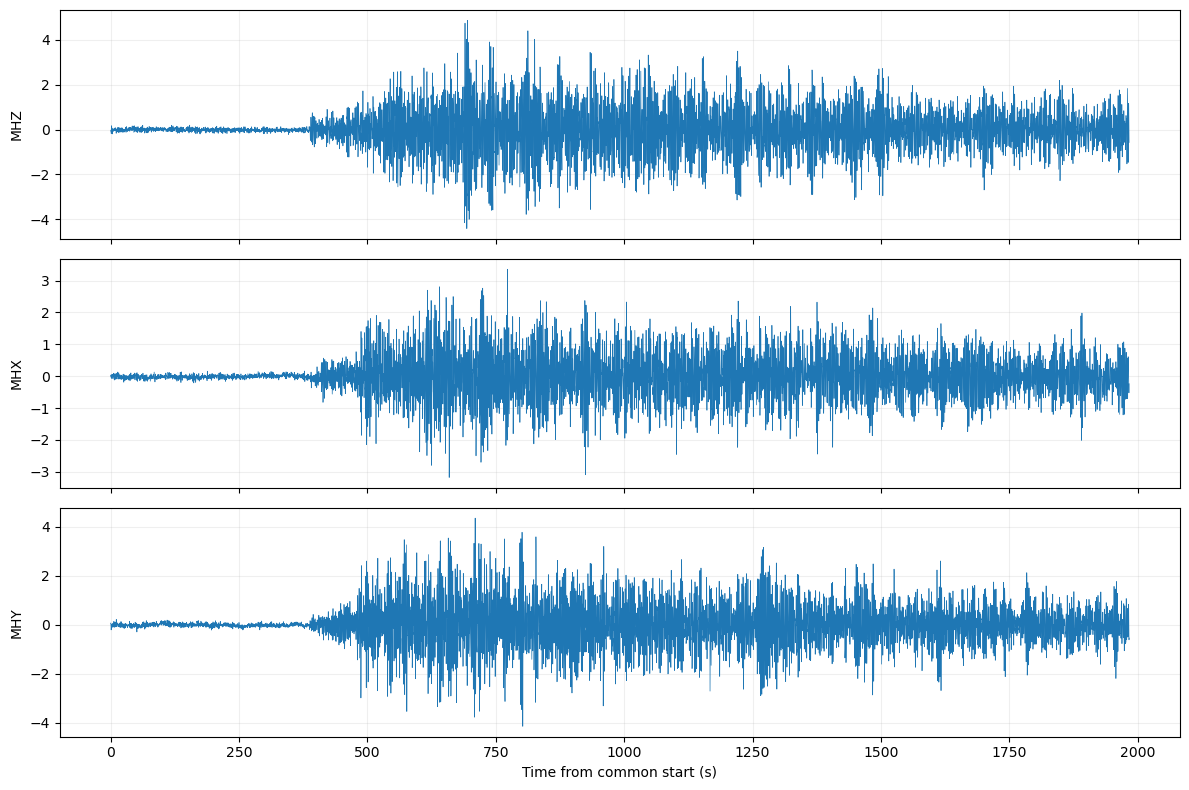

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, channel in zip(axes, ("MHZ", "MHX", "MHY")):
    ax.plot(time, components[channel], lw=0.5)
    ax.set_ylabel(channel)
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Time from common start (s)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "stacked_components.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Check the event catalog

The Nunn et al. (2020) `levent.1008c` file contains 13,058 events. The Apollo 12 waveform in Section 7 covers the A1 deep moonquake on 1973-09-30. Its cataloged signal begins at 04:12 UTC; the waveform starts earlier to include the pre-event record.

For the fixed-width column definitions and event-type codes, see the [catalog guide (EvCatEntries.1008.txt)](https://github.com/mpanning/lunar_catalog/blob/main/UTIGTR_0018/EvCatEntries.1008.txt).


In [6]:
lines = (data_dir / "levent.1008c").read_text(encoding="ascii", errors="replace").splitlines()
event_lines = [line for line in lines
               if line[2:4] == "73" and line[5:8] == "273" and line[9:13] == "0412"
               and line[81:85].strip() == "A  1"]
if len(event_lines) != 1:
    raise RuntimeError(f"Expected one A1 event on 1973-09-30 at 04:12; found {len(event_lines)}")
event_time = UTCDateTime("1973-09-30T04:12:00")
assert start <= event_time <= end
print("Catalog events:", len(lines))
print("A1 event time:", event_time)
print("Catalog entry:", event_lines[0])


Catalog events: 13058
A1 event time: 1973-09-30T04:12:00.000000Z
Catalog entry:   73 273 0412 0450 3.0 16.03.0 7.0  2222      OLD A46, INVERTED             A 01 A  1


## 7. Download the raw Apollo 12 records for the stack's reference event

EarthScope calls its horizontal channels MH1/MH2 rather than MHX/MHY.

In [7]:
client = Client("https://service.earthscope.org")
raw_stream = client.get_waveforms("XA", "S12", "00", "MH?", start, end)
raw_traces = {tr.stats.channel: tr for tr in raw_stream}
for channel in ("MHZ", "MH1", "MH2"):
    if channel not in raw_traces:
        raise RuntimeError(f"Missing EarthScope channel {channel}")
    print(raw_traces[channel])

XA.S12.00.MHZ | 1973-09-30T04:06:44.497412Z - 1973-09-30T04:39:47.591752Z | 6.6 Hz, 13139 samples
XA.S12.00.MH1 | 1973-09-30T04:06:44.610356Z - 1973-09-30T04:39:47.553752Z | 6.6 Hz, 13138 samples
XA.S12.00.MH2 | 1973-09-30T04:06:44.629356Z - 1973-09-30T04:39:47.572752Z | 6.6 Hz, 13138 samples


## 8. Compare the stacked and single-event waveforms

Align and bandpass both datasets with the same 0.05–1 Hz filter. The stack combines multiple events, so its waveform will not exactly match the single-event record. 

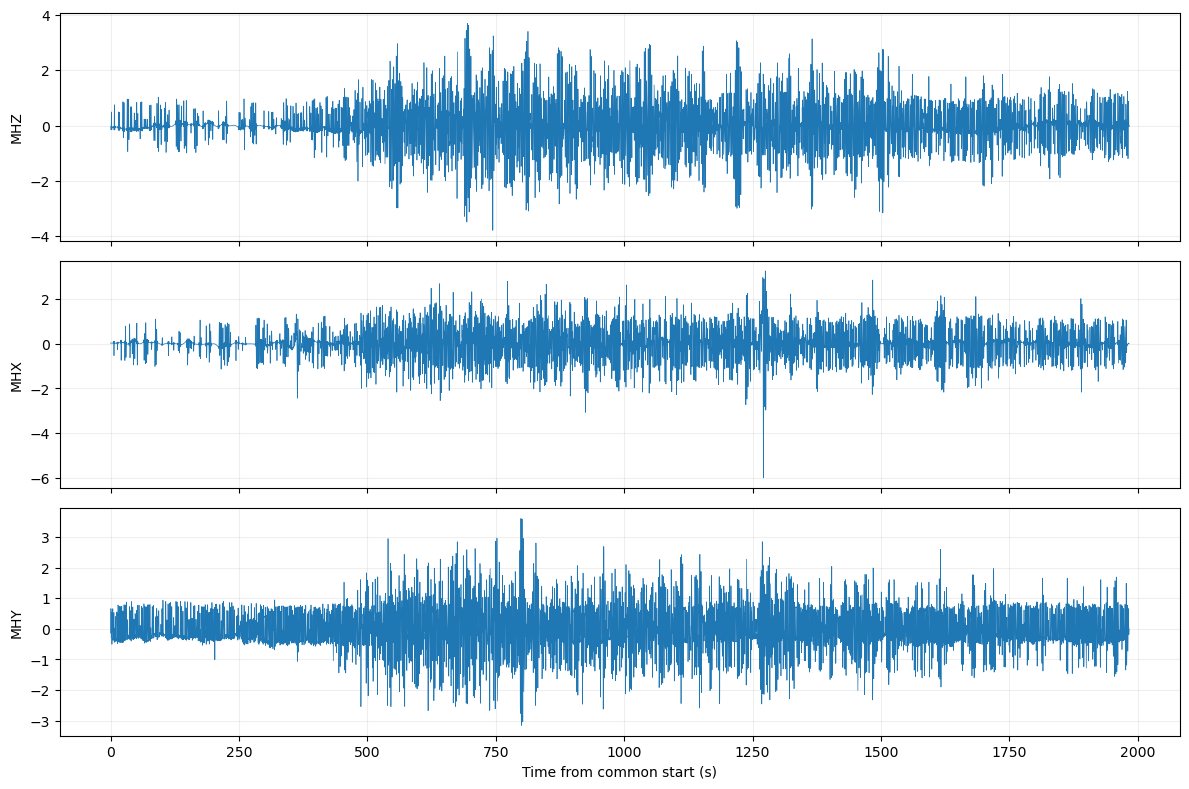

MHZ waveform correlation: 0.88


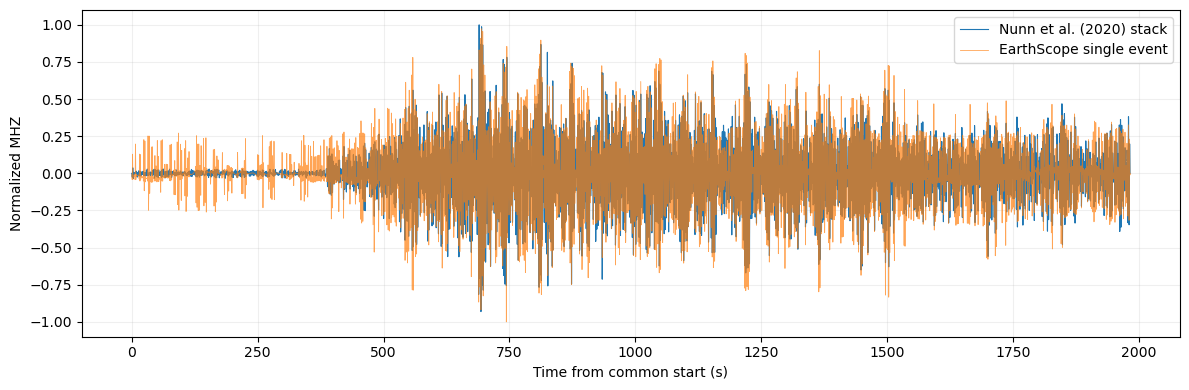

In [8]:
def bandpass_aligned(data):
    tr = Trace(np.asarray(data, dtype=float).copy(), header={"sampling_rate": sr})
    tr.detrend("demean")
    tr.detrend("linear")
    tr.filter("bandpass", freqmin=0.05, freqmax=1.0, corners=4, zerophase=True)
    return tr.data

stack_z = bandpass_aligned(components["MHZ"])
raw_filtered = {}
for stack_channel, raw_channel in (("MHZ", "MHZ"), ("MHX", "MH1"), ("MHY", "MH2")):
    source = raw_traces[raw_channel]
    aligned = np.interp(time, source.times(reftime=start), source.data.astype(float))
    raw_filtered[stack_channel] = bandpass_aligned(aligned)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, channel in zip(axes, ("MHZ", "MHX", "MHY")):
    ax.plot(time, raw_filtered[channel], lw=0.5)
    ax.set_ylabel(channel)
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Time from common start (s)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "raw_components.png", dpi=180, bbox_inches="tight")
plt.show()

stack_z_norm = stack_z / np.max(np.abs(stack_z))
raw_z_norm = raw_filtered["MHZ"] / np.max(np.abs(raw_filtered["MHZ"]))
print(f"MHZ waveform correlation: {np.corrcoef(stack_z_norm, raw_z_norm)[0, 1]:.2f}")
plt.figure(figsize=(12, 4))
plt.plot(time, stack_z_norm, lw=0.8, label="Nunn et al. (2020) stack")
plt.plot(time, raw_z_norm, lw=0.6, alpha=0.7, label="EarthScope single event")
plt.xlabel("Time from common start (s)")
plt.ylabel("Normalized MHZ")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "mhz_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## Sources

- [Nunn et al. (2020) lunar seismology data](https://doi.org/10.5281/zenodo.7787610)
- [EarthScope FDSN services](https://service.earthscope.org/fdsnws/)
- [Catalog guide (EvCatEntries.1008.txt)](https://github.com/mpanning/lunar_catalog/blob/main/UTIGTR_0018/EvCatEntries.1008.txt)